# <span style="color:green"> Numerical Simulation Laboratory </span>
## <span style="color:brown"> Python Exercise 11 </span>
## <span style="color:orange"> Keras - Neural Network regression </span>

In [4]:
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import backend as K
from tensorflow.keras.utils import get_custom_objects

2026-11-11 09:27:29.284389: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2, in other operations, rebuild TensorFlow with the appropriate compiler flags.


### Exercise 11.1

## Results

In this exercise, building upon the code provided during the lecture, we investigated the impact of three key parameters, the number of epochs ($N_{\mathrm{epochs}}$), the training set size ($N_{\mathrm{train}}$), and the noise level ($\sigma$), on the model's convergence and accuracy. Here I am going to report just three regimes to visualise the results; however, I tried this simulation for several combinations.

* **Regime 1 :** $N_{\mathrm{epochs}} = 40$, $N_{\mathrm{train}} = 300$, $\sigma = 0.4$
* **Regime 2 :** $N_{\mathrm{epochs}} = 40$, $N_{\mathrm{train}} = 300$, $\sigma = 0.09$
* **Regime 3 :** $N_{\mathrm{epochs}} = 80$, $N_{\mathrm{train}} = 1000$, $\sigma = 0.4$


| Regime | $m$ | $b$ | MSE (noisy validation) | MSE (exact line) |
|---|---|---|---|---|
| 1 | 1.768 | 0.957 | 0.166 | 0.0161 |
| 2 | 1.968 | 0.990 | 0.0078 | 0.0003 |
| 3 | 2.009 | 1.010 | 0.111 | 0.0001 |

Based on these configurations, here is the list of what I inferred:

* **Impact of the number of epochs ($N_{\mathrm{epochs}}$):** Increasing $N_{\mathrm{epochs}}$ gives the model more optimization steps to fit the training data, leading to a steady decrease in training loss. However, the validation loss typically improves at a slower rate, as the model's weights are not directly updated on the validation set. In more complex scenarios, an excessively high epoch count can lead to overfitting, where the network begins to memorize specific noise rather than learning the underlying trend.

* **Impact of training set size ($N_{\mathrm{train}}$):** Expanding $N_{\mathrm{train}}$ significantly enhances model performance, resulting in lower loss values on both training and validation sets. A larger and more diverse training dataset allows the model to capture the true underlying distribution more accurately, leading to strong generalization capabilities where validation loss closely tracks or rivals training loss.

* **Impact of noise ($\sigma$):** Increasing the noise level $\sigma$ results in greater dispersion of both training and validation data around the true underlying line. If $\sigma$ is excessively high, the dataset becomes less representative of the target function, making it difficult for the network to capture a coherent input-output relationship. Consequently, predictive performance degrades.







---
**Exercise**

In order to make practice with NN, explore how does the previous linear regression depend on the number of epochs, $N_{\mathrm{epochs}}$, the number of data points $N_{\mathrm{train}}$ and on the noise $\sigma$. Try to improve the previous result operating on these parameters.

In [31]:
import numpy as np
import matplotlib.pyplot as plt
# target parameters of f(x) = m*x + b
m = 2 # slope
b = 1 # intersect

### First Set of Parameters
- **Epochs ($N_{\mathrm{epochs}}$):** 40
- **Training points ($N_{\mathrm{train}}$):** 300
- **Noise ($\sigma$):** 0.4

**Obtained Parameters:** $m = 1.768$, $b = 0.956$  

In [23]:
# genero  300 punti training e 30 di validazione con rumore gaussiano 
np.random.seed(0)
x_train = np.random.uniform(-1, 1, 300)
x_valid = np.random.uniform(-1, 1, 30)
x_valid.sort()
y_target = m * x_valid + b # ideal (target) linear function

sigma = 0.4 # aumento devizione standard
y_train = np.random.normal(m * x_train + b, sigma) # actual measures from which we want to guess regression parameters
y_valid = np.random.normal(m * x_valid + b, sigma)

In [25]:
model = tf.keras.Sequential()
model.add(Input(shape=(1,))) # number od inputs
model.add(Dense(1)) # layer with only one neuron 

# compile the model choosing optimiser (stochastic gradient descent), loss and metrics objects
model.compile(optimizer='sgd', loss='mse', metrics=['mse']) 

In [27]:
history = model.fit(x=x_train, y=y_train, 
          batch_size=32, epochs=40,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          validation_data=(x_valid, y_valid))

# evaluate model
score = model.evaluate(x_valid, y_valid, batch_size=32, verbose=1)

# print performance : valuto modello con dati non visti
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

# evaluate model with the exact curve
score = model.evaluate(x_valid, y_target, batch_size=32, verbose=1)

# print performance : valuto modello con curva esatta
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

print("")
# return weights and biases
print(model.get_weights())

Epoch 1/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 4.2691 - mse: 4.2691 - val_loss: 2.9016 - val_mse: 2.9016
Epoch 2/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.5475 - mse: 3.5475 - val_loss: 2.5424 - val_mse: 2.5424
Epoch 3/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2.9945 - mse: 2.9945 - val_loss: 2.2425 - val_mse: 2.2425
Epoch 4/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.5516 - mse: 2.5516 - val_loss: 1.9972 - val_mse: 1.9972
Epoch 5/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.2149 - mse: 2.2149 - val_loss: 1.7775 - val_mse: 1.7775
Epoch 6/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.9252 - mse: 1.9252 - val_loss: 1.5908 - val_mse: 1.5908
Epoch 7/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.6813 - mse: 1.6813 - val_loss: 1.4174 - val_mse: 1.4174
Epoch 8/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.4763 - mse: 1.4763 - val_loss: 1.2736 - val_mse: 1.2736
Epoch 9/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3001 - ms

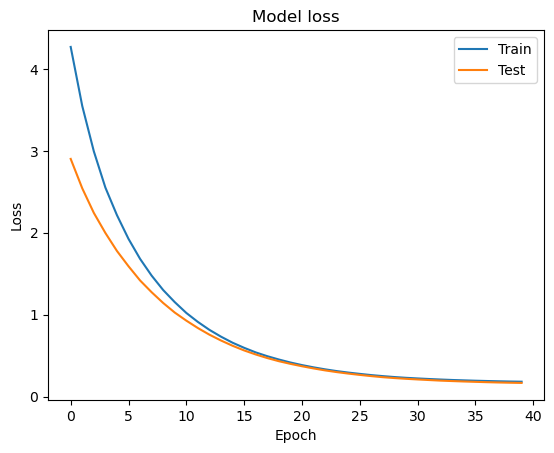

In [33]:
# look into training history
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='best')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


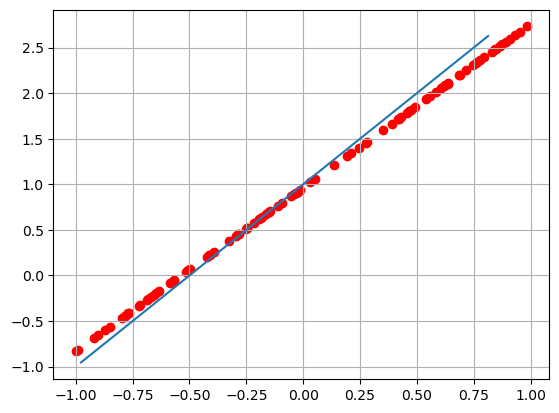

In [167]:
x_predicted = np.random.uniform(-1, 1, 100)
y_predicted = model.predict(x_predicted)
plt.scatter(x_predicted, y_predicted,color='r')
plt.plot(x_valid, y_target)
plt.grid(True)
plt.show()

### Second set of parameters
- **Epochs ($N_{\mathrm{epochs}}$):** 40
- **Training points ($N_{\mathrm{train}}$):** 300
- **Noise ($\sigma$):** 0.09

**Obtained Parameters:** $m = 1.968$, $b = 0.989$

In [170]:
# genero  300 punti training e 30 di validazione con rumore gaussiano 
np.random.seed(0)
x_train = np.random.uniform(-1, 1, 300)
x_valid = np.random.uniform(-1, 1, 30)
x_valid.sort()
y_target = m * x_valid + b # ideal (target) linear function

sigma = 0.09 # aumento devizione standard
y_train = np.random.normal(m * x_train + b, sigma) # actual measures from which we want to guess regression parameters
y_valid = np.random.normal(m * x_valid + b, sigma)

In [172]:
model = tf.keras.Sequential()
model.add(Input(shape=(1,))) # number od inputs
model.add(Dense(1)) # layer with only one neuron 

# compile the model choosing optimiser (stochastic gradient descent), loss and metrics objects
model.compile(optimizer='sgd', loss='mse', metrics=['mse']) 

In [174]:
history = model.fit(x=x_train, y=y_train, 
          batch_size=32, epochs=40,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          validation_data=(x_valid, y_valid))

# evaluate model
score = model.evaluate(x_valid, y_valid, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

# evaluate model with the exact curve
score = model.evaluate(x_valid, y_target, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

print("")
# return weights and biases
print(model.get_weights())

Epoch 1/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9052 - mse: 0.9052 - val_loss: 0.5785 - val_mse: 0.5785
Epoch 2/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6183 - mse: 0.6183 - val_loss: 0.3855 - val_mse: 0.3855
Epoch 3/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4243 - mse: 0.4243 - val_loss: 0.2582 - val_mse: 0.2582
Epoch 4/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2935 - mse: 0.2935 - val_loss: 0.1759 - val_mse: 0.1759
Epoch 5/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2066 - mse: 0.2066 - val_loss: 0.1216 - val_mse: 0.1216
Epoch 6/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1475 - mse: 0.1475 - val_loss: 0.0860 - val_mse: 0.0860
Epoch 7/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1073 - mse: 0.1073 - val_loss: 0.0622 - val_mse: 0.0622
Epoch 8/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0795 - mse: 0.0795 - val_loss: 0.0463 - val_mse: 0.0463
Epoch 9/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0601 - mse:

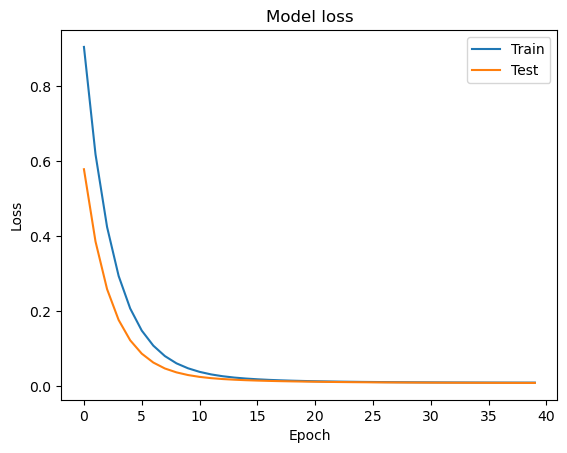

In [176]:
# look into training history
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='best')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


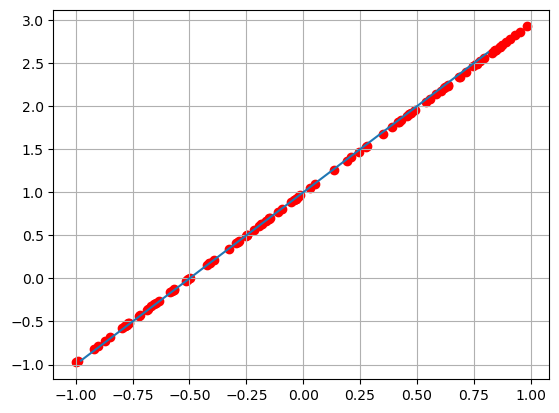

In [178]:
x_predicted = np.random.uniform(-1, 1, 100)
y_predicted = model.predict(x_predicted)
plt.scatter(x_predicted, y_predicted,color='r')
plt.plot(x_valid, y_target)
plt.grid(True)
plt.show()

### Third set of parameters
- **Epochs ($N_{\mathrm{epochs}}$):** 80
- **Training points ($N_{\mathrm{train}}$):** 1000
- **Noise ($\sigma$):** 0.4

**Obtained Parameters:** $m = 2.009$, $b = 1.009$

In [150]:
# genero  1000 punti training e 80 di validazione con rumore gaussiano 
np.random.seed(0)
x_train = np.random.uniform(-1, 1, 1000)
x_valid = np.random.uniform(-1, 1, 80)
x_valid.sort()
y_target = m * x_valid + b # ideal (target) linear function

sigma = 0.4 # aumento devizione standard
y_train = np.random.normal(m * x_train + b, sigma) # actual measures from which we want to guess regression parameters
y_valid = np.random.normal(m * x_valid + b, sigma)

In [152]:
model = tf.keras.Sequential()
model.add(Input(shape=(1,))) # number od inputs
model.add(Dense(1)) # layer with only one neuron 

# compile the model choosing optimiser (stochastic gradient descent), loss and metrics objects
model.compile(optimizer='sgd', loss='mse', metrics=['mse']) 

history = model.fit(x=x_train, y=y_train, 
          batch_size=32, epochs=80,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          validation_data=(x_valid, y_valid))


# evaluate model
score = model.evaluate(x_valid, y_valid, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])


# evaluate model with the exact curve
score = model.evaluate(x_valid, y_target, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])
print("")
# return weights and biases
print(model.get_weights())

Epoch 1/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.9771 - mse: 2.9771 - val_loss: 2.2666 - val_mse: 2.2666
Epoch 2/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.7780 - mse: 1.7780 - val_loss: 1.4631 - val_mse: 1.4631
Epoch 3/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1496 - mse: 1.1496 - val_loss: 0.9861 - val_mse: 0.9861
Epoch 4/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7815 - mse: 0.7815 - val_loss: 0.6859 - val_mse: 0.6859
Epoch 5/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5540 - mse: 0.5540 - val_loss: 0.4913 - val_mse: 0.4913
Epoch 6/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4122 - mse: 0.4122 - val_loss: 0.3638 - val_mse: 0.3638
Epoch 7/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3212 - mse: 0.3212 - val_loss: 0.2784 - val_mse: 0.2784
Epoch 8/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2614 - mse: 0.2614 - val_loss: 0.2239 - val_mse: 0.2239
Epoch 9/80
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2230 - mse: 

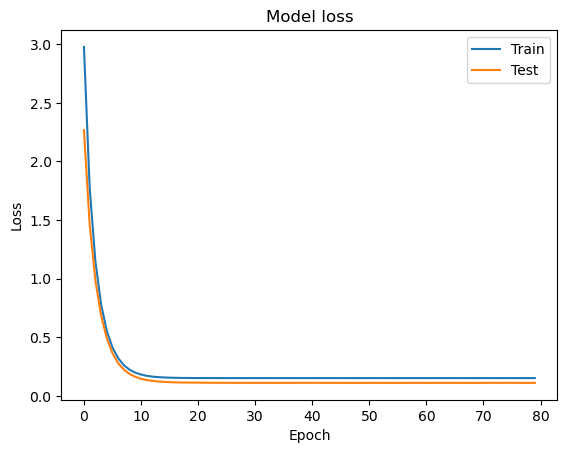

In [154]:
# look into training history
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='best')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


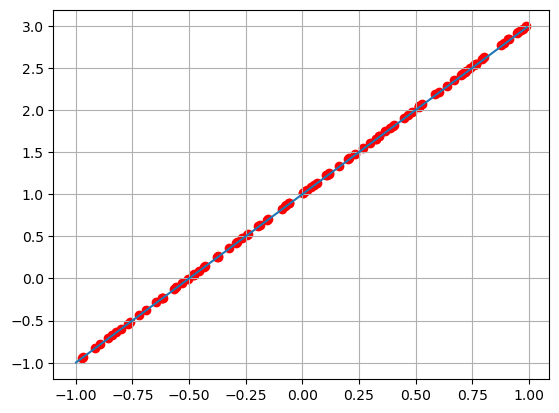

In [156]:
x_predicted = np.random.uniform(-1, 1, 100)
y_predicted = model.predict(x_predicted)
plt.scatter(x_predicted, y_predicted,color='r')
plt.plot(x_valid, y_target)
plt.grid(True)
plt.show()

# Exercise 11.2

## Results 

Exploiting the Universal Approximation Theorem, I initially tested a baseline model featuring a single hidden layer with 256 neurons. During this exploration, I compared both `ReLU` and `tanh` activation functions. I observed that `tanh` provides a smoother and more natural approximation for a continuous cubic polynomial compared to the piecewise-linear nature of `ReLU`.

For the primary analysis, the model was configured with the following parameters:
- **Noise level ($\sigma$):** $0.3$
- **Training dataset size ($N_{\mathrm{train}}$):** $50000$
- **Epochs ($N_{\mathrm{epochs}}$):** $60$

### Extended Architecture ("Plus" part)
To further optimize performance and enhance the model's capacity, I implemented an extended architecture featuring **two hidden layers**:
* **First hidden layer:** 64 neurons with `tanh` activation
* **Second hidden layer:** 32 neurons with `tanh` activation
* **Optimizer:** Adam

| Model | Architecture | Optimizer | Parameters | MSE (noisy validation) | MSE (exact curve) |
|---|---|---|---|---|---|
| Baseline | 1 hidden layer, 256 neurons, `tanh` | SGD | 769 | 0.0896 | 0.0015 |
| Extended ("Plus") | 2 hidden layers, 64 + 32 neurons, `tanh` | Adam | 2241 | 0.0883 | 0.00056 |

This deeper structure, combined with the Adam optimizer and a rich dataset of 50,000 points, improves the convergence rate.


**Inside the training range $[-1,1]$.** Both networks reproduce the polynomial well.

**Outside the training range ($x\in[-1.5,1.5]$).** Both networks fail to extrapolate.



---
**Exercise**

Try to extend the model to obtain a reasonable fit of the following polynomial of order 3:

$$
f(x)=4-3x-2x^2+3x^3
$$
for $x \in [-1,1]$.

Find good (& reasonable) choices for:

- the number of layers
- the number of neurons in each layer
- the activation function
- the optimizer
- the loss function
  
Check your NN model by seeing how well your fits predict newly generated test data (including on data outside the range you fit. How well do your NN do on points in the range of $x$ where you trained the model? How about points outside the original training data set? 
Summarize what you have learned about the relationship between model complexity (number of parameters), goodness of fit on training data, and the ability to predict well.

In [59]:
# parameters 
# y= ax^3 + bx^2 +cx +d 
a=3
b=-2
c=-3
d=4

# generate training inputs
np.random.seed(0)
x_train = np.random.uniform(-1, 1, 50000)
x_valid = np.random.uniform(-1, 1, 1000)
x_valid.sort()
y_target = a * x_valid**3 + b * x_valid**2 + c * x_valid + d 

sigma = 0.3 # noise standard deviation, for the moment it is absent
y_train = np.random.normal(a * x_train**3 + b * x_train**2 +c * x_train + d , sigma) # actual measures from which we want to guess regression parameters
y_valid = np.random.normal(a * x_valid**3 + b * x_valid**2 +c * x_valid + d , sigma)

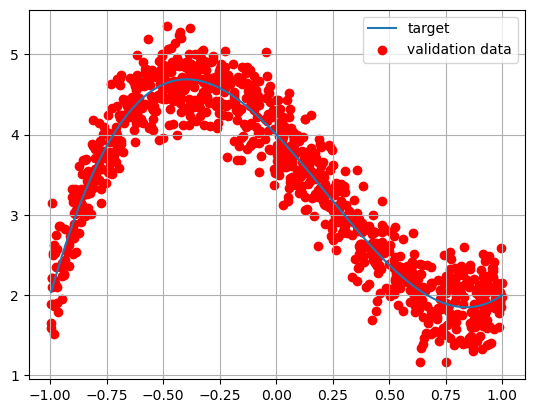

In [61]:
plt.plot(x_valid, y_target, label='target')
plt.scatter(x_valid, y_valid, color='r', label='validation data')
plt.legend()
plt.grid(True)
plt.show()

In [63]:
model = tf.keras.Sequential()
model.add(Input(shape=(1,))) # layer di input 
model.add(Dense(256, activation='tanh')) # hidden layer 
model.add(Dense(1)) # layer out 

# compile the model choosing optimiser, loss and metrics objects
model.compile(optimizer='sgd', loss='mse', metrics=['mse'])

# get a summary of our composed model
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 256)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 769 (3.00 KB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
history = model.fit(x=x_train, y=y_train, 
          batch_size=32, epochs=60,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          validation_data=(x_valid, y_valid))

Epoch 1/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 538us/step - loss: 0.7062 - mse: 0.7062 - val_loss: 0.6278 - val_mse: 0.6278
Epoch 2/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 460us/step - loss: 0.6263 - mse: 0.6263 - val_loss: 0.5807 - val_mse: 0.5807
Epoch 3/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 453us/step - loss: 0.4221 - mse: 0.4221 - val_loss: 0.2231 - val_mse: 0.2231
Epoch 4/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 467us/step - loss: 0.1615 - mse: 0.1615 - val_loss: 0.1349 - val_mse: 0.1349
Epoch 5/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 467us/step - loss: 0.1292 - mse: 0.1292 - val_loss: 0.1220 - val_mse: 0.1220
Epoch 6/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 499us/step - loss: 0.1189 - mse: 0.1189 - val_loss: 0.1137 - val_mse: 0.1137
Epoch 7/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 468us/step - loss: 0.1118 - mse: 0.1118 - val_loss: 0.1095 - val_mse: 0.1095
Epoch 8/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 454us/step - loss: 0.1065 - mse: 0.1065 - val_loss: 0.1055 - val_mse: 0.1055
Epoch 9/60
1563/1563 ━━━

In [68]:
# return weights and biases
model.get_weights()
# evaluate model
score = model.evaluate(x_valid, y_valid, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 975us/step - loss: 0.0896 - mse: 0.0896

Test loss: 0.08963052928447723
Test accuracy: 0.08963052928447723


In [70]:
# evaluate model with the exact curve
score = model.evaluate(x_valid, y_target, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0015 - mse: 0.0015 

Test loss: 0.0015205268282443285
Test accuracy: 0.0015205268282443285


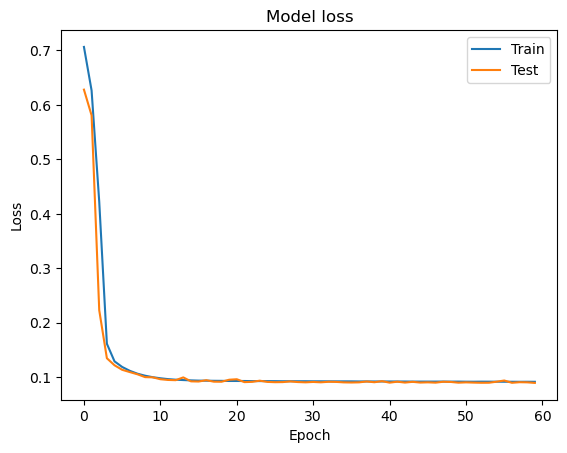

In [72]:
# look into training history
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='best')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


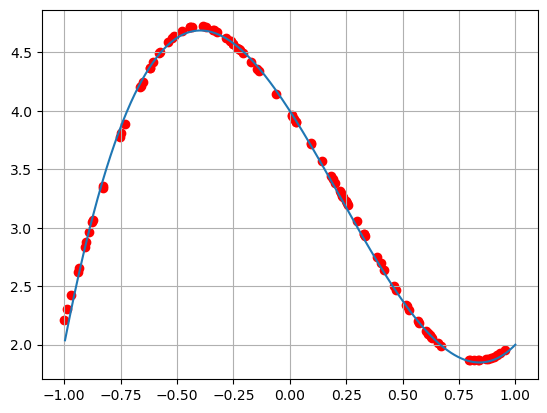

In [74]:
x_predicted = np.random.uniform(-1, 1, 100)
y_predicted = model.predict(x_predicted)
plt.scatter(x_predicted, y_predicted,color='r')
plt.plot(x_valid, y_target)
plt.grid(True)
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


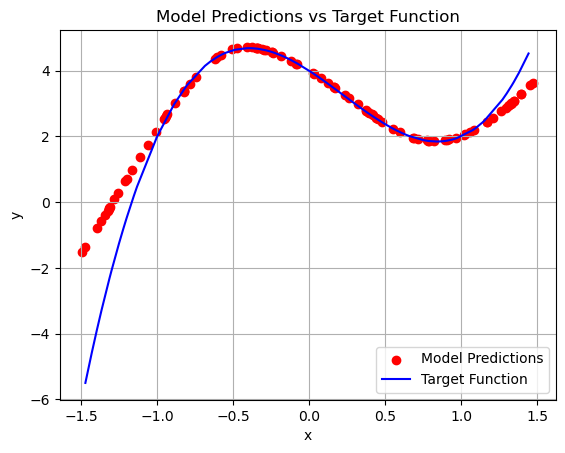

In [78]:
x_predicted = np.random.uniform(-1.5, 1.5, 100)
x_valid=np.random.uniform(-1.5,1.5,100)
x_valid.sort()
y_target=a * x_valid**3 + b * x_valid**2 + c * x_valid + d
y_predicted = model.predict(x_predicted)

plt.title("Model Predictions vs Target Function")
plt.scatter(
    x_predicted, y_predicted, color="r", label="Model Predictions"
)  
plt.plot(x_valid, y_target, color="b", label="Target Function")  # True curve
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

# Plus

In [80]:
# parameters 
# y= ax^3 + bx^2 +cx +d 
a=3
b=-2
c=-3
d=4

# generate training inputs
np.random.seed(0)
x_train = np.random.uniform(-1, 1, 50000)
x_valid = np.random.uniform(-1, 1, 600)
x_valid.sort()
y_target = a * x_valid**3 + b * x_valid**2 + c * x_valid + d 

sigma = 0.3 # noise standard deviation, for the moment it is absent
y_train = np.random.normal(a * x_train**3 + b * x_train**2 +c * x_train + d , sigma) # actual measures from which we want to guess regression parameters
y_valid = np.random.normal(a * x_valid**3 + b * x_valid**2 +c * x_valid + d , sigma)



model = tf.keras.Sequential()
model.add(Input(shape=(1,))) # Input layer 
model.add(Dense(64, activation='tanh')) # First hidden layer with tanh
model.add(Dense(32, activation='tanh'))  # Second hidden layer with tanh
model.add(Dense(1)) # Output layer 

# Compile the model with a different optimizer (e.g., 'adam')
model.compile(optimizer='adam', loss='mse', metrics=['mse'])


In [82]:
history = model.fit(x=x_train, y=y_train, 
          batch_size=32, epochs=60,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          validation_data=(x_valid, y_valid))

# return weights and biases
model.get_weights()
# evaluate model
score = model.evaluate(x_valid, y_valid, batch_size=32, verbose=1)


Epoch 1/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 523us/step - loss: 0.4513 - mse: 0.4513 - val_loss: 0.1016 - val_mse: 0.1016
Epoch 2/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 517us/step - loss: 0.0985 - mse: 0.0985 - val_loss: 0.0976 - val_mse: 0.0976
Epoch 3/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 513us/step - loss: 0.0948 - mse: 0.0948 - val_loss: 0.0919 - val_mse: 0.0919
Epoch 4/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 487us/step - loss: 0.0946 - mse: 0.0946 - val_loss: 0.0901 - val_mse: 0.0901
Epoch 5/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 511us/step - loss: 0.0941 - mse: 0.0941 - val_loss: 0.0975 - val_mse: 0.0975
Epoch 6/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 498us/step - loss: 0.0939 - mse: 0.0939 - val_loss: 0.0938 - val_mse: 0.0938
Epoch 7/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 519us/step - loss: 0.0931 - mse: 0.0931 - val_loss: 0.0901 - val_mse: 0.0901
Epoch 8/60
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 517us/step - loss: 0.0934 - mse: 0.0934 - val_loss: 0.0898 - val_mse: 0.0898
Epoch 9/60
1563/1563 ━━━

In [84]:
# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

# evaluate model with the exact curve
score = model.evaluate(x_valid, y_target, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])


Test loss: 0.08833807706832886
Test accuracy: 0.08833807706832886
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 5.5514e-04 - mse: 5.5514e-04 

Test loss: 0.0005551414215005934
Test accuracy: 0.0005551414215005934


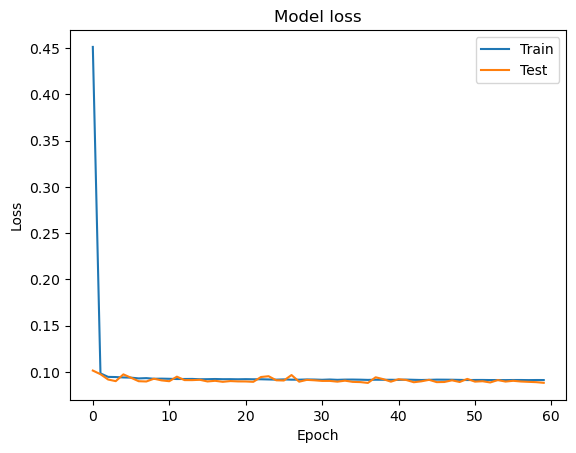

In [86]:
# look into training history
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='best')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


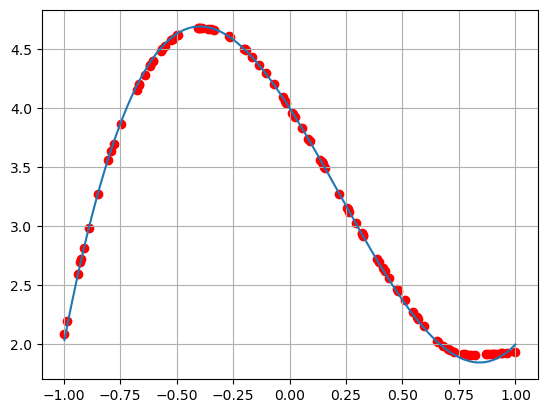

In [88]:
x_predicted = np.random.uniform(-1, 1, 100)
y_predicted = model.predict(x_predicted)
plt.scatter(x_predicted, y_predicted,color='r')
plt.plot(x_valid, y_target)
plt.grid(True)
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


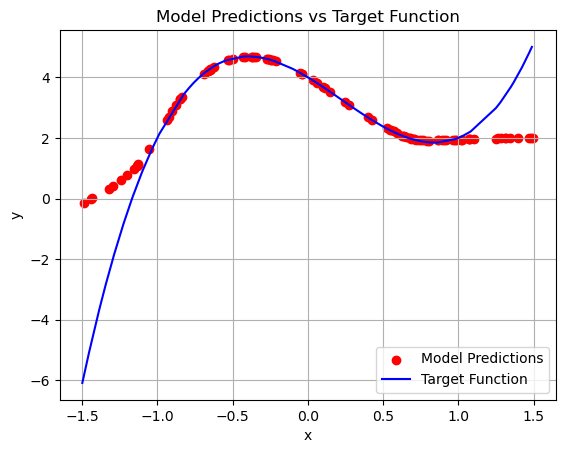

In [90]:
x_predicted = np.random.uniform(-1.5, 1.5, 100)
x_valid=np.random.uniform(-1.5,1.5,100)
x_valid.sort()
y_target=a * x_valid**3 + b * x_valid**2 + c * x_valid + d
y_predicted = model.predict(x_predicted)

plt.title("Model Predictions vs Target Function")
plt.scatter(
    x_predicted, y_predicted, color="r", label="Model Predictions"
)  
plt.plot(x_valid, y_target, color="b", label="Target Function")  # True curve
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

# Exercise 11.3

## Result

Building upon the previous exercise, I extended the neural network architecture to fit a 2D trigonometric function, $f(x,y) = \sin(x^2+y^2)$, within the domain $x, y \in [-3/2, 3/2]$. 

For this multi-variable regression task, the model and training configuration were set as follows:
- **Training dataset size ($N_{\mathrm{train}}$):** $40000$ points (to adequately sample the 2D input space)
- **Noise level ($\sigma$):** $0.3$
- **Epochs ($N_{\mathrm{epochs}}$):** $60$
- **Hidden Layers:** Two hidden layers with 128 and 64 neurons
- **Activation Function:** `tanh` 
- **Optimizer:** Adam








---
**Exercise**
  
Try to extend the model to fit a simple trigonometric 2D function such as $f(x,y) = \sin(x^2+y^2)$ in the range $x \in [-3/2,3/2]$ and $y \in [-3/2,3/2]$.

In [92]:
# parameters 
a=1
b=1

# generate training inputs
np.random.seed(0)
x_train = np.random.uniform(-(3.0/2), (3.0/2), 40000)
x_valid = np.random.uniform(-(3.0/2), (3.0/2), 4000)

y_train = np.random.uniform(-(3.0/2), (3.0/2), 40000)
y_valid = np.random.uniform(-(3.0/2), (3.0/2), 4000)
z_target = np.sin(a*x_valid**2 + b*y_valid**2) 

sigma = 0.3 # noise standard deviation, for the moment it is absent
z_train = np.random.normal(np.sin(x_train**2 + y_train**2)  , sigma) # actual measures from which we want to guess regression parameters
z_valid = np.random.normal(np.sin(x_valid**2 + y_valid**2)  , sigma)

In [94]:
model = tf.keras.Sequential()
model.add(Input(shape=(2,)))                 
model.add(Dense(128, activation='tanh'))      
model.add(Dense(64, activation='tanh'))      
model.add(Dense(1))                          

model.compile(optimizer='adam', loss='mse', metrics=['mse'])
model.summary() 


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,705 (34.00 KB)

 Trainable params: 8,705 (34.00 KB)

 Non-trainable params: 0 (0.00 B)

In [96]:
X_train_3D = np.column_stack((x_train, y_train))
X_valid_3D = np.column_stack((x_valid, y_valid))

history = model.fit(
    x=X_train_3D,          # Matrice di input (3000 righe x 2 colonne: X e Y)
    y=z_train,             # Il target da indovinare (3000 valori della coordinata Z)
    batch_size=32, 
    epochs=60,             # Alziamo leggermente i cicli: fittare in 3D richiede più tempo!
    shuffle=True, 
    validation_data=(X_valid_3D, z_valid) # Input e target di validazione
)

Epoch 1/60
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 594us/step - loss: 0.2473 - mse: 0.2473 - val_loss: 0.2392 - val_mse: 0.2392
Epoch 2/60
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 535us/step - loss: 0.2411 - mse: 0.2411 - val_loss: 0.2360 - val_mse: 0.2360
Epoch 3/60
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 533us/step - loss: 0.2395 - mse: 0.2395 - val_loss: 0.2380 - val_mse: 0.2380
Epoch 4/60
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 534us/step - loss: 0.2385 - mse: 0.2385 - val_loss: 0.2373 - val_mse: 0.2373
Epoch 5/60
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 534us/step - loss: 0.2379 - mse: 0.2379 - val_loss: 0.2375 - val_mse: 0.2375
Epoch 6/60
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 538us/step - loss: 0.2373 - mse: 0.2373 - val_loss: 0.2350 - val_mse: 0.2350
Epoch 7/60
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 545us/step - loss: 0.2370 - mse: 0.2370 - val_loss: 0.2375 - val_mse: 0.2375
Epoch 8/60
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 538us/step - loss: 0.2363 - mse: 0.2363 - val_loss: 0.2354 - val_mse: 0.2354
Epoch 9/60
1250/1250 ━━━

In [98]:
# return weights and biases
model.get_weights()
# evaluate model
score = model.evaluate(X_valid_3D, z_valid, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 597us/step - loss: 0.0922 - mse: 0.0922

Test loss: 0.09224678575992584
Test accuracy: 0.09224678575992584


In [100]:
# evaluate model with the exact curve
score = model.evaluate(X_valid_3D, z_target, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 568us/step - loss: 0.0037 - mse: 0.0037

Test loss: 0.003737818915396929
Test accuracy: 0.003737818915396929


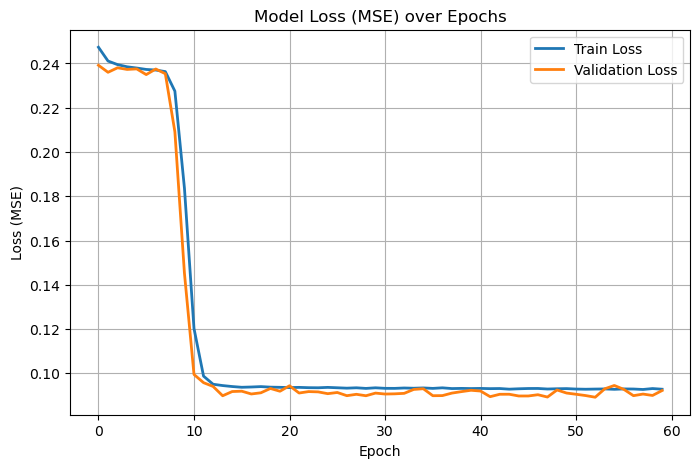

In [102]:
# Plot training & validation loss values
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('Model Loss (MSE) over Epochs')
plt.ylabel('Loss (MSE)')
plt.xlabel('Epoch')
plt.legend(loc='best')
plt.grid(True)
plt.show()

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


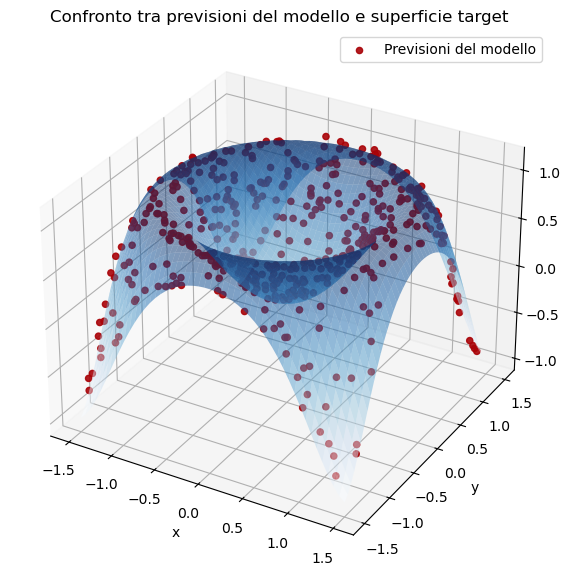

In [104]:
x_predicted = np.random.uniform(-3/2, 3/2, 500)
y_predicted = np.random.uniform(-3/2, 3/2, 500)
xy_predicted = np.column_stack((x_predicted, y_predicted))

z_predicted = model.predict(xy_predicted)

grid_x = np.linspace(-3/2, 3/2, 50)
grid_y = np.linspace(-3/2, 3/2, 50)
x_grid, y_grid = np.meshgrid(grid_x, grid_y)


z_grid = np.sin(x_grid**2 + y_grid**2)



fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(x_grid, y_grid, z_grid, cmap='Blues', alpha=0.5, edgecolor='none')

ax.scatter(x_predicted, y_predicted, z_predicted.flatten(), color='xkcd:darkish red', s=20, label='Previsioni del modello', alpha=0.9)


ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Confronto tra previsioni del modello e superficie target')
ax.legend()

plt.show()